# t002 — Hybrid ARIMA–GRU dự báo giá đồng

Mô hình lai kiểu Zhang (2003): ARIMA bắt phần tuyến tính, GRU học phần dư của ARIMA.
Dự báo cuối = dự báo ARIMA + phần dư GRU dự báo.

So sánh 4 mô hình: **Naive** (giá hôm qua), **ARIMA**, **GRU** (dự báo thẳng giá), **Hybrid**.
Dữ liệu: bộ 9 hàng hóa của Khoa (2016–2026), chỉ dùng giá đồng ($/lb). Dự báo 1 phiên tới, cửa sổ 22 phiên,
chia train/test theo thời gian 80/20, 90/10, 92.5/7.5, 95/5 (giống Khoa).

Chạy trên Kaggle (có TensorFlow). Trên máy không có TensorFlow thì phần GRU/Hybrid tự bỏ qua.

## 1. Cấu hình

In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import pmdarima
except ImportError:  # Kaggle có thể chưa cài sẵn
    %pip install -q pmdarima
    import pmdarima
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm

try:
    import tensorflow as tf
    HAS_TF = True
except ImportError:
    HAS_TF = False

ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    found = glob.glob('/kaggle/input/**/commodities_9_daily.csv', recursive=True)
    assert found, 'Chưa thêm file commodities_9_daily.csv vào Kaggle (Add Input)'
    DATA_PATH, OUT_DIR = found[0], '/kaggle/working/t002'
else:
    DATA_PATH, OUT_DIR = '../data/raw/dataset_9_commodities_daily.csv', 'result'  # chạy trong thư mục 'huy task'
os.makedirs(OUT_DIR, exist_ok=True)

TARGET = 'Copper'
SPLITS = [0.8, 0.9, 0.925, 0.95]
LOOKBACK = 22
SEEDS = [41, 42, 43, 44, 45]   # giống Khoa; giảm bớt nếu muốn chạy nhanh
EPOCHS, BATCH, PATIENCE, LR, UNITS = 100, 64, 10, 1e-3, 64
VAL_FRAC = 0.1        # 10% cuối của train làm validation cho early stopping (không dùng test)
WARMUP = 30           # bỏ vài phiên đầu: dự báo in-sample của ARIMA lúc đầu chưa ổn định

print('TensorFlow:', HAS_TF, '| Kaggle:', ON_KAGGLE, '| data:', DATA_PATH)

Note: you may need to restart the kernel to use updated packages.


I0000 00:00:1795107264.977475      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795107278.865868      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: True | Kaggle: True | data: /kaggle/input/datasets/huyphan726/copper-9-commodities/commodities_9_daily.csv


## 2. Dữ liệu

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
y = df[TARGET].astype(float).values
dates = df['Date'].values
n = len(y)
assert not np.isnan(y).any(), 'Có giá trị thiếu trong chuỗi giá đồng'
print(n, 'phiên,', df['Date'].min().date(), '->', df['Date'].max().date())

for name, s in [('Mức giá', y), ('Sai phân bậc 1', np.diff(y))]:
    stat, p = adfuller(s)[:2]
    print(f'ADF {name}: stat={stat:.3f}, p={p:.4f} ->', 'dừng' if p < 0.05 else 'không dừng')

2710 phiên, 2016-01-13 -> 2026-11-13
ADF Mức giá: stat=-0.846, p=0.8053 -> không dừng
ADF Sai phân bậc 1: stat=-22.980, p=0.0000 -> dừng


/tmp/ipykernel_16/2380301144.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s)[:2]
/tmp/ipykernel_16/2380301144.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s)[:2]


## 3. Hàm dùng chung

- `arima_one_step`: chọn (p,d,q) bằng `auto_arima` **chỉ trên train**, rồi giữ nguyên tham số và chạy bộ lọc
  trên cả chuỗi để lấy dự báo 1 bước. Dự báo tại phiên t chỉ dùng dữ liệu tới t−1 → không rò rỉ test.
- `windows`: tạo mẫu (22 giá trị trước → giá trị phiên t) cho các phiên t trong `idx`.
- `fit_gru`: GRU 1 lớp + Dense, early stopping trên validation cắt từ cuối train.

In [3]:
def metrics(actual, pred):
    err = actual - pred
    return {
        'MAE': np.mean(np.abs(err)),
        'RMSE': np.sqrt(np.mean(err ** 2)),
        'MAPE (%)': 100 * np.mean(np.abs(err / actual)),
        'R2': 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }


def dm_test(actual, pred, base, power=1):
    # Diebold-Mariano: d_t = |e_model|^p - |e_base|^p; phương sai HAC Newey-West.
    # stat < 0: mô hình sai số nhỏ hơn base. p-value hai phía.
    d = np.abs(actual - pred) ** power - np.abs(actual - base) ** power
    if np.allclose(d, 0):
        return np.nan, np.nan            # hai dự báo trùng nhau, không kiểm định được
    lags = int(4 * (len(d) / 100) ** (2 / 9))
    res = sm.OLS(d, np.ones_like(d)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return res.tvalues[0], res.pvalues[0]


def arima_one_step(y, train_end):
    am = auto_arima(y[:train_end], test='adf', seasonal=False, stepwise=True,
                    suppress_warnings=True, error_action='ignore')
    order = am.order
    if am.with_intercept:
        trend = 't' if order[1] == 1 else 'c'   # d=1: hằng số trên chuỗi sai phân = drift
    else:
        trend = 'n'
    if order[1] >= 2:
        trend = 'n'
    res = ARIMA(y[:train_end], order=order, trend=trend).fit()
    full = res.apply(y)                       # tham số fit trên train, không ước lượng lại
    pred = full.get_prediction().predicted_mean
    return pred, order, trend


def windows(series, idx, lookback=LOOKBACK):
    X = np.stack([series[t - lookback:t] for t in idx])[..., None]
    return X, series[idx]


def fit_gru(X_tr, y_tr, X_val, y_val, seed):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=X_tr.shape[1:]),
        tf.keras.layers.GRU(UNITS),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss='mse')
    stop = tf.keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)
    model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=EPOCHS,
              batch_size=BATCH, callbacks=[stop], verbose=0)
    return model


def gru_predict(series, train_end, test_idx, seed):
    # chuẩn hoá bằng thống kê của phần train, rồi train GRU dự báo series[t] từ 22 giá trị trước
    first = WARMUP + LOOKBACK   # cửa sổ đầu tiên không chạm vào phần warm-up
    val_start = train_end - int((train_end - first) * VAL_FRAC)
    mu, sd = series[first:val_start].mean(), series[first:val_start].std()
    z = (series - mu) / sd
    X_tr, y_tr = windows(z, np.arange(first, val_start))
    X_val, y_val = windows(z, np.arange(val_start, train_end))
    X_te, _ = windows(z, test_idx)
    model = fit_gru(X_tr, y_tr, X_val, y_val, seed)
    return model.predict(X_te, verbose=0).ravel() * sd + mu

Kiểm tra rò rỉ: đổi giá phiên cuối thì dự báo ARIMA của chính phiên đó phải không đổi.

In [4]:
_te = int(n * SPLITS[0])
_p1, _, _ = arima_one_step(y, _te)
_y2 = y.copy(); _y2[-1] *= 1.5
_p2, _, _ = arima_one_step(_y2, _te)
assert np.isclose(_p1[-1], _p2[-1]), 'ARIMA dùng giá của chính phiên cần dự báo!'
assert np.allclose(_p1[:-1], _p2[:-1])
print('OK: dự báo ARIMA tại t chỉ dùng dữ liệu tới t-1')

# kiểm tra hàm DM: dự báo cộng nhiễu lớn phải kém base rõ rệt (stat > 0, p nhỏ)
_rng = np.random.default_rng(0)
_a = y[-300:]; _b = y[-301:-1]
_s, _p = dm_test(_a, _b + _rng.normal(0, 0.2, 300), _b)
assert _s > 0 and _p < 0.01, (_s, _p)
assert np.isnan(dm_test(_a, _b, _b)[0])
print(f'OK: DM phát hiện dự báo kém hơn (stat={_s:.1f}, p={_p:.1e})')

OK: dự báo ARIMA tại t chỉ dùng dữ liệu tới t-1
OK: DM phát hiện dự báo kém hơn (stat=12.4, p=3.9e-35)


## 4. Chạy 4 tỷ lệ chia

Với mỗi tỷ lệ r: train = `int(n·r)` phiên đầu, test = phần còn lại (80/20 → 542 phiên test, giống Khoa).
Phần dư ARIMA `e_t = y_t − ARIMA_t`; GRU học e_t từ 22 phần dư trước đó (đều đã biết tại phiên t).

In [5]:
rows, all_preds = [], {}
for r in SPLITS:
    train_end = int(n * r)
    test_idx = np.arange(train_end, n)
    actual = y[test_idx]

    arima_pred, order, trend = arima_one_step(y, train_end)
    resid = y - arima_pred
    preds = {'Naive': y[test_idx - 1], 'ARIMA': arima_pred[test_idx]}

    runs = [('Naive', None, preds['Naive']), ('ARIMA', None, preds['ARIMA'])]
    if HAS_TF:
        for seed in SEEDS:
            g = gru_predict(y, train_end, test_idx, seed)
            h = arima_pred[test_idx] + gru_predict(resid, train_end, test_idx, seed)
            runs += [('GRU', seed, g), ('Hybrid ARIMA-GRU', seed, h)]
            preds[f'GRU_s{seed}'], preds[f'Hybrid_s{seed}'] = g, h
            print(f'  split {r:g} seed {seed} xong')
        # trung bình qua seed, chỉ để vẽ hình; số liệu báo cáo lấy theo từng seed ở bảng dưới
        preds['GRU'] = np.mean([p for n_, s_, p in runs if n_ == 'GRU'], axis=0)
        preds['Hybrid ARIMA-GRU'] = np.mean([p for n_, s_, p in runs if n_ == 'Hybrid ARIMA-GRU'], axis=0)

    split = f'{r:g}/{1 - r:.3g}'
    for name, seed, p in runs:
        dm1, p1 = dm_test(actual, p, preds['Naive'], 1)
        dm2, p2 = dm_test(actual, p, preds['Naive'], 2)
        rows.append({'Split': split, 'Test': len(test_idx), 'Mô hình': name, 'Seed': seed,
                     **metrics(actual, p), 'DM L1': dm1, 'p L1': p1, 'DM L2': dm2, 'p L2': p2})
    all_preds[r] = pd.DataFrame({'Date': dates[test_idx], 'Actual': actual, **preds})
    all_preds[r].to_csv(f'{OUT_DIR}/predictions_{r:g}.csv', index=False)
    print(f'split {r:g}: ARIMA{order} trend={trend}, test={len(test_idx)}')

results = pd.DataFrame(rows)   # mỗi dòng = 1 mô hình × 1 seed × 1 split
results.to_csv(f'{OUT_DIR}/results_by_seed.csv', index=False)
results.round(6)

E0000 00:00:1795107292.253513      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


  split 0.8 seed 41 xong
  split 0.8 seed 42 xong
  split 0.8 seed 43 xong
  split 0.8 seed 44 xong
  split 0.8 seed 45 xong
split 0.8: ARIMA(0, 1, 0) trend=n, test=542


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


  split 0.9 seed 41 xong
  split 0.9 seed 42 xong
  split 0.9 seed 43 xong
  split 0.9 seed 44 xong
  split 0.9 seed 45 xong
split 0.9: ARIMA(0, 1, 0) trend=n, test=271
  split 0.925 seed 41 xong
  split 0.925 seed 42 xong
  split 0.925 seed 43 xong
  split 0.925 seed 44 xong
  split 0.925 seed 45 xong
split 0.925: ARIMA(2, 1, 2) trend=n, test=204
  split 0.95 seed 41 xong
  split 0.95 seed 42 xong
  split 0.95 seed 43 xong
  split 0.95 seed 44 xong
  split 0.95 seed 45 xong
split 0.95: ARIMA(2, 1, 2) trend=n, test=136


,Split,Test,Mô hình,Seed,MAE,RMSE,MAPE (%),R2,DM L1,p L1,DM L2,p L2
0,0.8/0.2,542,Naive,NaN,0.069001,0.108000,1.289379,0.983303,NaN,NaN,NaN,NaN
1,0.8/0.2,542,ARIMA,NaN,0.069001,0.108000,1.289379,0.983303,NaN,NaN,NaN,NaN
2,0.8/0.2,542,GRU,41.0,0.221291,0.301218,3.715431,0.870116,7.988620,0.000000,6.680471,0.000000
3,0.8/0.2,542,Hybrid ARIMA-GRU,41.0,0.068890,0.107918,1.287470,0.983328,-0.878144,0.379866,-0.531686,0.594944
4,0.8/0.2,542,GRU,42.0,0.238879,0.324484,4.009388,0.849276,8.168510,0.000000,6.682523,0.000000
5,0.8/0.2,542,Hybrid ARIMA-GRU,42.0,0.069327,0.108280,1.295530,0.983216,1.265061,0.205850,1.113198,0.265623
6,0.8/0.2,542,GRU,43.0,0.233441,0.317421,3.917365,0.855766,8.099334,0.000000,6.671781,0.000000
7,0.8/0.2,542,Hybrid ARIMA-GRU,43.0,0.069308,0.108390,1.295431,0.983182,1.167795,0.242890,1.355514,0.175254
8,0.8/0.2,542,GRU,44.0,0.194423,0.263864,3.284112,0.900332,7.841744,0.000000,6.644390,0.000000
9,0.8/0.2,542,Hybrid ARIMA-GRU,44.0,0.068997,0.108096,1.289565,0.983273,-0.025853,0.979374,0.503142,0.614865


## 5. Tổng hợp qua các seed và kiểm định Diebold–Mariano so với Naive

- MAE/RMSE/MAPE/R²: trung bình (và độ lệch chuẩn MAE) qua các seed. Naive, ARIMA không có seed.
- ΔMAE (%): âm = tốt hơn Naive. Tham chiếu: GRU Residual tốt nhất của Khoa chỉ hơn Naive < 0.6%.
- DM (loss L1 = sai số tuyệt đối, L2 = bình phương), phương sai HAC. `DM < 0` = sai số nhỏ hơn Naive.
  Cột `Số seed p<0.05 (L1)`: bao nhiêu seed hơn/kém Naive có ý nghĩa ở mức 5% — giống cách Khoa báo theo seed.

In [6]:
order_models = ['Naive', 'ARIMA', 'GRU', 'Hybrid ARIMA-GRU']
summary = (results.groupby(['Split', 'Mô hình'], sort=False)
           .agg(MAE=('MAE', 'mean'), MAE_std=('MAE', 'std'), RMSE=('RMSE', 'mean'),
                **{'MAPE (%)': ('MAPE (%)', 'mean')}, R2=('R2', 'mean'),
                **{'DM L1 (tb)': ('DM L1', 'mean'), 'p L1 (tb)': ('p L1', 'mean'),
                   'Số seed p<0.05 (L1)': ('p L1', lambda s: int((s < 0.05).sum())),
                   'Số seed': ('Seed', 'count')})
           .reset_index())
naive = summary[summary['Mô hình'] == 'Naive'].set_index('Split')['MAE']
summary.insert(3, 'ΔMAE vs Naive (%)', 100 * (summary['MAE'] / summary['Split'].map(naive) - 1))
summary.to_csv(f'{OUT_DIR}/results.csv', index=False)
summary.round(6)

,Split,Mô hình,MAE,ΔMAE vs Naive (%),MAE_std,RMSE,MAPE (%),R2,DM L1 (tb),p L1 (tb),Số seed p<0.05 (L1),Số seed
0,0.8/0.2,Naive,0.069001,0.000000,NaN,0.108000,1.289379,0.983303,NaN,NaN,0,0
1,0.8/0.2,ARIMA,0.069001,0.000000,NaN,0.108000,1.289379,0.983303,NaN,NaN,0,0
2,0.8/0.2,GRU,0.225625,226.985877,0.018963,0.307197,3.788048,0.864108,8.016814,0.000000,5,5
3,0.8/0.2,Hybrid ARIMA-GRU,0.069225,0.324086,0.000285,0.108274,1.293931,0.983218,0.590128,0.392614,0,5
4,0.9/0.1,Naive,0.077077,0.000000,NaN,0.101033,1.277697,0.957855,NaN,NaN,0,0
5,0.9/0.1,ARIMA,0.077077,0.000000,NaN,0.101033,1.277697,0.957855,NaN,NaN,0,0
6,0.9/0.1,GRU,0.299463,288.525542,0.021518,0.337178,4.777185,0.528947,11.768193,0.000000,5,5
7,0.9/0.1,Hybrid ARIMA-GRU,0.076758,-0.413948,0.000064,0.100747,1.272277,0.958093,-1.900379,0.084511,2,5
8,0.925/0.075,Naive,0.075116,0.000000,NaN,0.098399,1.208127,0.923818,NaN,NaN,0,0
9,0.925/0.075,ARIMA,0.074556,-0.745757,NaN,0.098132,1.198805,0.924231,-1.159319,0.246326,0,0


In [7]:
summary.pivot(index='Mô hình', columns='Split', values='ΔMAE vs Naive (%)').loc[order_models].round(3)

Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
Mô hình,,,,
Naive,0.000,0.000,0.000,0.000
ARIMA,0.000,0.000,-0.746,-0.307
GRU,226.986,288.526,352.428,377.185
Hybrid ARIMA-GRU,0.324,-0.414,-0.939,-0.442


## 6. Biểu đồ thực tế vs dự báo

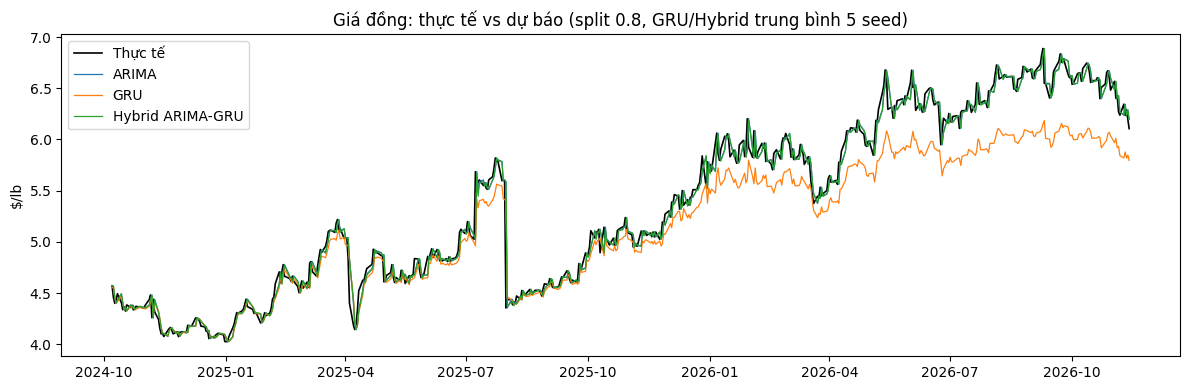

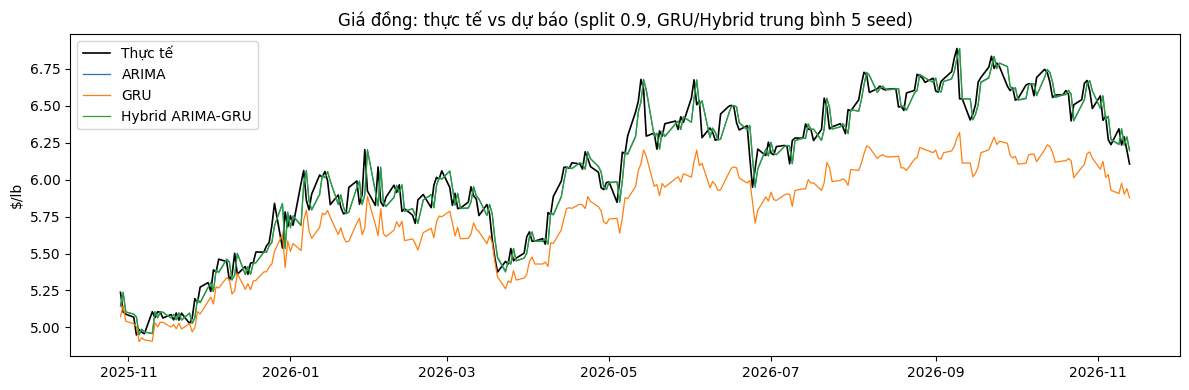

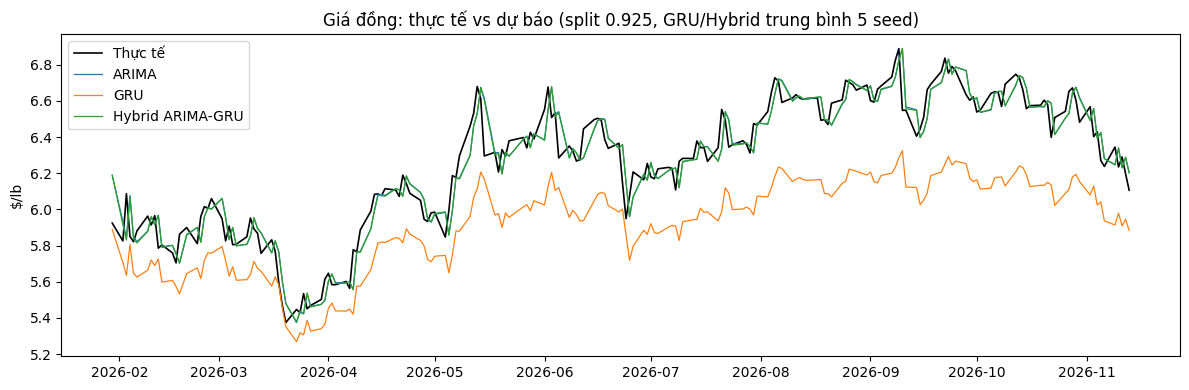

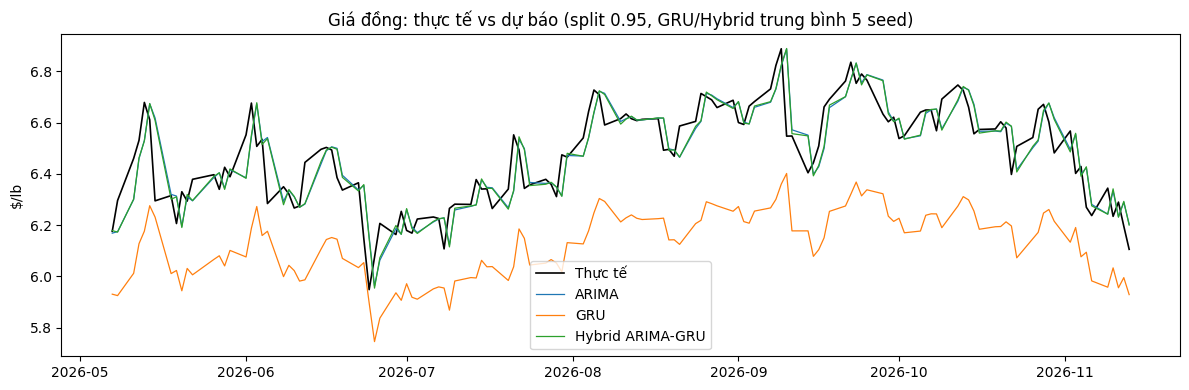

Đã lưu kết quả vào /kaggle/working/t002


In [8]:
for r, p in all_preds.items():
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(p['Date'], p['Actual'], color='black', lw=1.2, label='Thực tế')
    for name in [c for c in ('ARIMA', 'GRU', 'Hybrid ARIMA-GRU') if c in p.columns]:
        ax.plot(p['Date'], p[name], lw=0.9, label=name)
    ax.set_title(f'Giá đồng: thực tế vs dự báo (split {r:g}, GRU/Hybrid trung bình {len(SEEDS)} seed)')
    ax.set_ylabel('$/lb')
    ax.legend()
    fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/actual_vs_pred_{r:g}.png', dpi=150)
    plt.show()
print('Đã lưu kết quả vào', OUT_DIR)